# 两只股票的五模型最终测试

在 `RUN_NAMES` 中指定两个测试实验目录，选择 **EE6008 → Restart Kernel → Run All**。


## 1. 模型结果表格

每只股票一张表，合并五模型与三个简单基线，按**方向准确率降序**排列。

- **Direction accuracy / Up F1**：方向准确率与上涨类 F1，结合真实和预测上涨比例、固定多数方向基线阅读。
- **MAE / RMSE**：越低越好，单位为收益百分点（pp）；**R2 / R2 vs zero** 分别参照评价期均值与零收益，越高越好。
- 方向按原始收益是否大于零判断，平盘归入“不涨”。所有表格指标使用完整测试期。

In [5]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'main.py').is_file() and (p / 'src/evaluate.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('请从 stock_prediction 或 notebooks 目录打开此 Notebook')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import src.evaluate as evaluation
if Path(evaluation.__file__).resolve() != (ROOT / 'src/evaluate.py').resolve():
    raise RuntimeError('评价模块来自其他项目目录，请重启内核')

# 必填：两个测试实验目录名。不会自动查找最新目录，也不会退回其他实验。
RUN_NAMES = ['aapl_final_test_02', 'tsla_final_test_02']

# 只决定局部预测曲线显示最后多少个测试交易日。
# 它不是模型的历史输入窗口（window=60），不影响完整测试期指标。
RECENT_DAYS = 80

MODELS = ['xgboost', 'lightgbm', 'patchtst', 'lstm', 'gru']
BASELINES = ['zero_return', 'historical_mean', 'last_return']
LABELS = dict(zip(MODELS + BASELINES,
    ['XGBoost', 'LightGBM', 'PatchTST', 'LSTM', 'GRU',
     'Zero return', 'Historical mean', 'Last return']))
COLORS = dict(zip(MODELS, ['#4477AA', '#EE9944', '#228866', '#AA4499', '#CC6677']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

In [6]:
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8-sig'))


def load_test_run(name):
    if not isinstance(name, str) or re.fullmatch(r'[A-Za-z0-9_-]+', name) is None:
        raise ValueError('请只填写 artifacts 下的实验目录名，不填写路径')
    folder = ROOT / 'artifacts' / name
    json_names = ['config', 'manifest', 'preprocessing', 'metrics', 'data_audit',
                  'direction_reference', 'source_manifest', 'validation_replay', 'inference']
    required = [f'{key}.json' for key in json_names] + ['predictions.csv']
    missing = [file for file in required if not (folder / file).is_file()]
    if missing:
        raise FileNotFoundError(f'{name} 缺少：{missing}')
    run = {key:read_json(folder / f'{key}.json') for key in json_names}
    run['name'] = name
    c, m, pre, audit = (run[key] for key in ['config','manifest','preprocessing','data_audit'])
    expected = {'status':'complete', 'evaluation_split':'test', 'test_evaluated':True,
                'retrained':False, 'preprocessing_fitted':False, 'holdout_evaluated':False}
    if any(m.get(key) != value for key,value in expected.items()):
        raise ValueError(f'{name}: 不是已完成、未重训且未使用保留期的测试实验')
    if not isinstance(c.get('ticker'), str) or not c['ticker'].strip():
        raise ValueError(f'{name}: config.json 缺少股票代码')
    if not set(MODELS).issubset(m.get('models_requested', [])):
        raise ValueError(f'{name}: manifest 缺少五模型记录')
    if m.get('seed') != c.get('seed') or not m.get('data_sha256'):
        raise ValueError(f'{name}: 随机种子或数据指纹记录错误')
    src = run['source_manifest']
    if (not m.get('source_run') or src.get('status') != 'complete'
            or src.get('evaluation_split') != 'validation'
            or src.get('data_sha256') != m['data_sha256']
            or src.get('seed') != c.get('seed')):
        raise ValueError(f'{name}: 模型来源记录不一致')
    if (run['inference'].get('source_run') != m['source_run']
            or run['inference'].get('retrained') is not False
            or not set(MODELS).issubset(run['inference'].get('models', {}))
            or run['validation_replay'].get('status') != 'passed'):
        raise ValueError(f'{name}: 推理来源或验证重现记录不一致')
    full = [prefix + f for prefix in ['', 'nasdaq_']
            for f in ['return','vol_change','intraday_return','range']]
    mode = c.get('nasdaq_features', 'all')
    if mode not in ['all','return_volume']:
        raise ValueError(f'{name}: 不支持的特征模式')
    features = full if mode == 'all' else full[:6]
    if (pre.get('features') != features or pre.get('window') != c.get('window')
            or audit.get('features') != features or audit.get('window') != c.get('window')):
        raise ValueError(f'{name}: 特征或窗口记录不一致')
    for key in ['feature_mean','feature_scale']:
        values = np.asarray(pre[key], dtype=float)
        if values.shape != (len(features),) or not np.isfinite(values).all():
            raise ValueError(f'{name}: 无效的保存预处理参数 {key}')
    if (not (np.asarray(pre['feature_scale']) > 0).all()
            or not np.isfinite([pre['target_mean'],pre['target_scale']]).all()
            or pre['target_scale'] <= 0):
        raise ValueError(f'{name}: 保存的缩放参数无效')
    lower, upper, holdout = map(pd.Timestamp, [c['validation_end'],c['test_end'],c['holdout_end']])
    if not lower < upper < holdout:
        raise ValueError(f'{name}: 测试期边界错误')
    if (audit.get('evaluation_split') != 'test' or audit.get('split_by') != 'target_date'
            or audit.get('read_cutoff') != str(upper.date())
            or audit.get('target_after') != str(lower.date())
            or audit.get('target_through') != str(upper.date())
            or audit.get('preprocessing_fitted') is not False
            or audit.get('holdout_evaluated') is not False):
        raise ValueError(f'{name}: 数据审计与测试区间不一致')
    pred = pd.read_csv(folder / 'predictions.csv', float_precision='round_trip')
    dates = ['window_start','signal_date','target_date']
    required_columns = dates + ['actual_return','actual_direction'] + MODELS + BASELINES
    if not set(required_columns).issubset(pred.columns):
        raise ValueError(f'{name}: 缺少日期、真实标签、模型或基线预测')
    for column in dates:
        pred[column] = pd.to_datetime(pred[column], errors='raise')
    if (len(pred) < 2 or pred[dates].isna().any().any()
            or pred.target_date.duplicated().any() or not pred.target_date.is_monotonic_increasing):
        raise ValueError(f'{name}: 日期缺失、重复、未排序或样本不足')
    if not ((pred.window_start <= pred.signal_date) & (pred.signal_date < pred.target_date)
            & (pred.target_date > lower) & (pred.target_date <= upper)).all():
        raise ValueError(f'{name}: 存在非因果窗口或测试区间之外的预测')
    if (len(pred) != audit.get('samples')
            or str(pred.target_date.min().date()) != audit.get('target_first')
            or str(pred.target_date.max().date()) != audit.get('target_last')):
        raise ValueError(f'{name}: 预测样本数或日期与审计不一致')
    np.testing.assert_array_equal(pred.actual_direction, (pred.actual_return > 0).astype(int))
    np.testing.assert_allclose(pred.zero_return, 0, rtol=0, atol=1e-12)
    np.testing.assert_allclose(pred.historical_mean, pre['target_mean'], rtol=0, atol=1e-12)
    metrics = {}
    for model in BASELINES + MODELS:
        if model not in run['metrics']:
            raise ValueError(f'{name}: metrics.json 缺少 {model}')
        metrics[model] = evaluation.evaluate(pred.actual_return.to_numpy(), pred[model].to_numpy())
        for key,value in metrics[model].items():
            saved = run['metrics'][model][key]
            if value is None or saved is None:
                if value != saved:
                    raise ValueError(f'{name}: {model}/{key} 指标不一致')
            else:
                np.testing.assert_allclose(value, saved, rtol=1e-8, atol=1e-12,
                    err_msg=f'{name}: {model}/{key} 与逐日预测不一致')
    ref = run['direction_reference']
    if not isinstance(ref.get('train_majority_up'), bool):
        raise ValueError(f'{name}: 训练期多数方向记录缺失')
    np.testing.assert_allclose(ref['test_accuracy'],
        np.mean((pred.actual_return > 0) == ref['train_majority_up']), rtol=0, atol=1e-12)
    run.update(ticker=c['ticker'], predictions=pred, metrics=metrics)
    return run


if not isinstance(RUN_NAMES, (list,tuple)) or len(RUN_NAMES) != 2 or len(set(RUN_NAMES)) != 2:
    raise ValueError('RUN_NAMES 必须指定两个不同的测试实验目录')
# 新一轮加载前清除旧汇总变量；出错时应修正目录并重新 Run All。
runs = []
loaded = [load_test_run(name) for name in RUN_NAMES]
if len({run['ticker'] for run in loaded}) != 2:
    raise ValueError('本页用于两只不同股票；同一股票前后实验应另作比较')
runs = loaded
for run in runs:
    print(f"{run['ticker']} | {run['name']} | 模型来源：{run['manifest']['source_run']}")
    print(f"测试期：{run['data_audit']['target_first']} 至 {run['data_audit']['target_last']}，{len(run['predictions'])} 个目标日")

AAPL | aapl_final_test_02 | 模型来源：aapl_compare_all_02
测试期：2024-01-02 至 2025-12-31，502 个目标日
TSLA | tsla_final_test_02 | 模型来源：tsla_compare_all_02
测试期：2024-01-02 至 2025-12-31，502 个目标日


In [7]:
# 每只股票一张表：五模型与三个基线合并，按方向准确率降序排列。
# 同分保留原顺序；全部指标使用完整测试期，RECENT_DAYS 仅影响后面的曲线。
columns = ['n', 'direction_accuracy', 'up_f1', 'actual_up_rate', 'predicted_up_rate',
           'mae', 'rmse', 'r2', 'r2_vs_zero']
result_tables = {}
for run in runs:
    display(Markdown(f"### {run['ticker']}"))
    table = pd.DataFrame(run['metrics']).T.loc[MODELS + BASELINES, columns].astype(float)
    table = table.sort_values('direction_accuracy', ascending=False, kind='stable')
    table['n'] = table['n'].astype(int)
    table[['mae', 'rmse']] *= 100  # 小数收益转为收益百分点，仅用于展示。
    table = table.rename(index=LABELS, columns={'n': 'N', 'direction_accuracy': 'Direction accuracy',
        'up_f1': 'Up F1', 'actual_up_rate': 'Actual up rate', 'predicted_up_rate': 'Predicted up rate',
        'mae': 'MAE (pp)', 'rmse': 'RMSE (pp)', 'r2': 'R2', 'r2_vs_zero': 'R2 vs zero'})
    table.index.name = 'Model'
    result_tables[run['name']] = table
    display(table.style.format({'N': '{:d}', 'Direction accuracy': '{:.2%}',
        'Up F1': '{:.4f}', 'Actual up rate': '{:.2%}', 'Predicted up rate': '{:.2%}',
        'MAE (pp)': '{:.4f}', 'RMSE (pp)': '{:.4f}', 'R2': '{:.4f}', 'R2 vs zero': '{:.4f}'}, na_rep='N/A'))
    print(f"训练期固定多数方向的测试准确率：{run['direction_reference']['test_accuracy']:.2%}")

### AAPL

,N,Direction accuracy,Up F1,Actual up rate,Predicted up rate,MAE (pp),RMSE (pp),R2,R2 vs zero
Model,,,,,,,,,
LightGBM,502,55.18%,0.6647,54.38%,79.28%,1.1723,1.7842,-0.0272,-0.0248
Historical mean,502,54.38%,0.7045,54.38%,100.00%,1.1559,1.7608,-0.0004,0.0019
XGBoost,502,52.79%,0.6784,54.38%,92.43%,1.1663,1.7696,-0.0105,-0.0082
Last return,502,52.59%,0.5641,54.38%,54.38%,1.5930,2.4307,-0.9064,-0.9020
GRU,502,52.39%,0.6739,54.38%,91.63%,1.1596,1.7587,0.0019,0.0042
LSTM,502,51.99%,0.6181,54.38%,71.31%,1.1437,1.7030,0.0642,0.0663
PatchTST,502,49.60%,0.5600,54.38%,60.16%,1.2623,1.8372,-0.0892,-0.0867
Zero return,502,45.62%,0.0000,54.38%,0.00%,1.1609,1.7624,-0.0023,0.0000


训练期固定多数方向的测试准确率：54.38%


### TSLA

,N,Direction accuracy,Up F1,Actual up rate,Predicted up rate,MAE (pp),RMSE (pp),R2,R2 vs zero
Model,,,,,,,,,
LightGBM,502,51.99%,0.5922,50.40%,67.33%,2.9446,4.0468,-0.0275,-0.0250
XGBoost,502,50.40%,0.6054,50.40%,75.30%,2.9056,3.9935,-0.0006,0.0019
Historical mean,502,50.40%,0.6702,50.40%,100.00%,2.8946,3.9928,-0.0002,0.0022
Zero return,502,49.60%,0.0000,50.40%,0.00%,2.8874,3.9972,-0.0024,0.0000
LSTM,502,49.40%,0.5753,50.40%,68.73%,2.9149,4.0260,-0.0169,-0.0145
Last return,502,49.00%,0.4941,50.40%,50.40%,4.2105,5.6904,-1.0316,-1.0266
PatchTST,502,47.61%,0.4368,50.40%,42.63%,3.0624,4.1627,-0.0872,-0.0845
GRU,502,47.61%,0.6237,50.40%,88.84%,2.9011,4.0041,-0.0059,-0.0035


训练期固定多数方向的测试准确率：50.40%


## 2. 模型预测曲线

每只股票单独展示一组图，每行一个模型：**左侧为完整测试期，右侧为最近 80 个交易日**；灰线为真实收益，彩线为模型预测收益。同一股票的各子图共享纵轴范围，方便比较。

右侧展示长度由 `RECENT_DAYS = 80` 控制，不改变模型历史输入窗口或完整测试期指标。


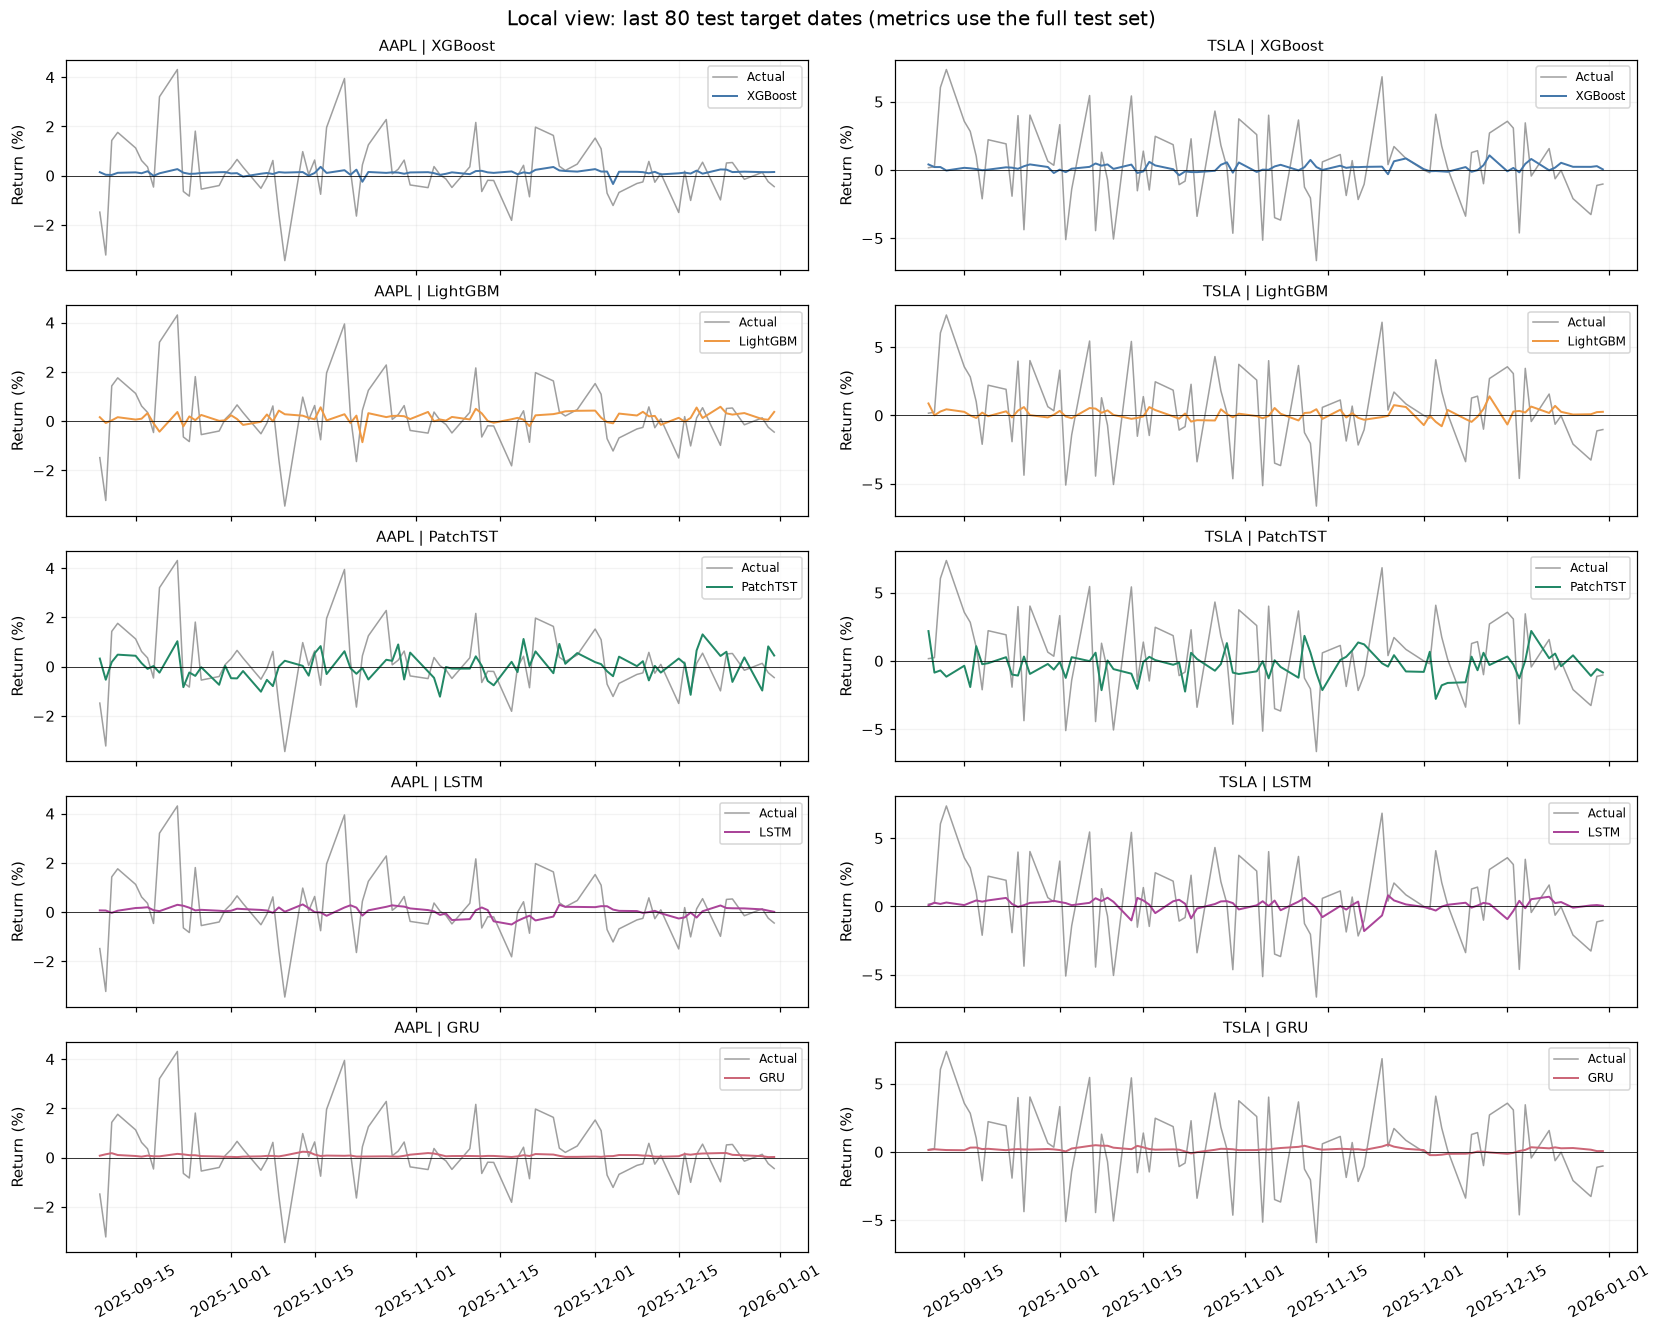

In [9]:
if not isinstance(RECENT_DAYS, int) or isinstance(RECENT_DAYS, bool) or RECENT_DAYS < 1:
    raise ValueError('RECENT_DAYS 必须为正整数')
fig, axes = plt.subplots(len(MODELS), len(runs), figsize=(15, 12), squeeze=False,
                         sharex='col', sharey='col', layout='constrained')
for j, run in enumerate(runs):
    recent = run['predictions'].tail(RECENT_DAYS)
    for i, model in enumerate(MODELS):
        ax = axes[i,j]
        ax.plot(recent.target_date, recent.actual_return*100, color='#777777', lw=1, alpha=.7, label='Actual')
        ax.plot(recent.target_date, recent[model]*100, color=COLORS[model], lw=1.3, label=LABELS[model])
        ax.axhline(0, color='black', lw=.5)
        ax.set_title(f"{run['ticker']} | {LABELS[model]}", fontsize=10)
        ax.set_ylabel('Return (%)')
        ax.grid(alpha=.15)
        ax.legend(fontsize=8, loc='upper right')
    axes[-1,j].tick_params(axis='x', labelrotation=30)
fig.suptitle(f'Local view: last {RECENT_DAYS} test target dates (metrics use the full test set)', fontsize=13)
plt.show()
plt.close(fig)